# 12 · FARS 2024 – US fatal crashes (NHTSA)

**Utility for the City Brain: medium** · Domain: accidents · Incident types: `accident`

> Every fatal crash in the US in 2024 with time, road, weather, light and the times when emergency services were notified and arrived.

| | |
|---|---|
| **Source** | US NHTSA Fatality Analysis Reporting System, `FARS2024NationalCSV.zip` |
| **Licence** | Public (US government); acknowledge NHTSA |
| **In this repo** | Sample: the `accident` table with 22 useful columns (`data/accidents/fars-2024/accident_2024_sample.csv.gz`) |
| **Get it** | https://www.nhtsa.gov/file-downloads?p=nhtsa/downloads/FARS/2024/National/ (33 tables, 390 MB) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

One row per fatal crash. The sample keeps: case id, state, month, weekday, hour / minute, rural or urban, road class, latitude / longitude, first harmful event, manner of collision, light and weather, **EMS notification time (`NOT_HOUR`, `NOT_MIN`), EMS arrival (`ARR_*`), hospital arrival (`HOSP_*`)**, persons and fatalities. Codes 88 / 98 / 99 mean "not applicable / unknown".

In [2]:
f = pd.read_csv(path('accidents/fars-2024/accident_2024_sample.csv.gz'))
print(f"{len(f):,} fatal crashes, {f.FATALS.sum():,} deaths"); f.head(3)

36,297 fatal crashes, 39,254 deaths


,ST_CASE,STATENAME,MONTH,DAY_WEEK,HOUR,MINUTE,RUR_URBNAME,FUNC_SYSNAME,LATITUDE,LONGITUD,HARM_EVNAME,MAN_COLLNAME,LGT_CONDNAME,WEATHERNAME,NOT_HOUR,NOT_MIN,ARR_HOUR,ARR_MIN,HOSP_HR,HOSP_MN,PERSONS,FATALS
0,10001,Alabama,1,2,10,30,Rural,Minor Arterial,33.471311,-87.496703,Tree (Standing Only),The First Harmful Event was Not a Collision wi...,Daylight,Clear,10,53,10,55,88,88,1,1
1,10002,Alabama,1,3,7,40,Urban,Other Principal Arterial,33.467956,-86.778806,Traffic Sign Support,The First Harmful Event was Not a Collision wi...,Daylight,Clear,7,40,7,45,88,88,1,1
2,10003,Alabama,1,3,6,20,Urban,Minor Arterial,30.633831,-87.852061,Pedestrian,The First Harmful Event was Not a Collision wi...,Dark - Not Lighted,Clear,6,20,6,28,88,88,2,1


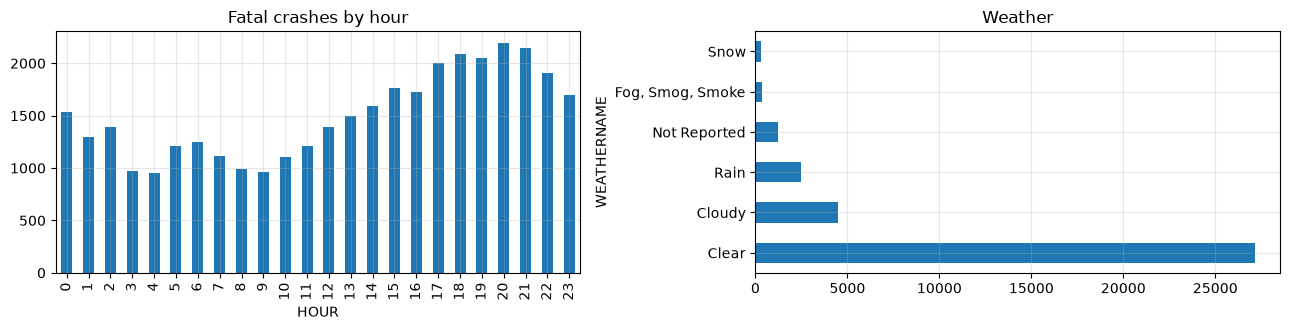

,% light condition
LGT_CONDNAME,
Daylight,45.0
Dark - Not Lighted,27.0
Dark - Lighted,22.0
Dusk,3.0
Dawn,2.0


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
f[f.HOUR < 24].HOUR.value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Fatal crashes by hour')
f.WEATHERNAME.value_counts().head(6).plot(kind='barh', ax=ax[1], title='Weather'); plt.tight_layout(); plt.show()
f.LGT_CONDNAME.value_counts(normalize=True).head(5).mul(100).round(0).to_frame('% light condition')

## 2. Emergency response times

EMS notification -> arrival: median 7 min, p90 18 min (14,716 crashes with both times)


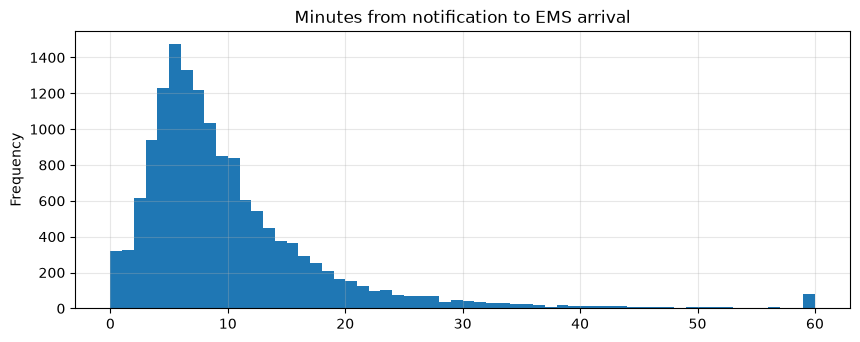

By area:


,median min
RUR_URBNAME,
Not Reported,7.0
Rural,10.0
Trafficway Not in State Inventory,6.0
Unknown,5.0
Urban,6.0


In [4]:
def minutes(h, m):
    ok = (h < 24) & (m < 60)
    return (h * 60 + m).where(ok)
notif, arr, hosp = minutes(f.NOT_HOUR, f.NOT_MIN), minutes(f.ARR_HOUR, f.ARR_MIN), minutes(f.HOSP_HR, f.HOSP_MN)
eta = ((arr - notif) % 1440).where(lambda s: s <= 180)
print(f"EMS notification -> arrival: median {eta.median():.0f} min, p90 {eta.quantile(.9):.0f} min ({eta.notna().sum():,} crashes with both times)")
eta.clip(upper=60).plot(kind='hist', bins=60, title='Minutes from notification to EMS arrival'); plt.show()
print('By area:'); eta.groupby(f.RUR_URBNAME).median().to_frame('median min')

## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Score** | Unit ETA prior for the scoring model: median ≈ 7 min, p90 ≈ 18 min; urban faster than rural |
| **Mock** | Accident priors by hour × weather × light for generating accident calls |
| **Scenarios** | Night / rain / dark-road accident cases |

**Limits:** fatal crashes only (biased toward severe), US roads, no sensor data.